In [223]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from typing import Any, Callable
import yfinance as yf

# Obtaining Prices for Analysis

In [224]:
# Stock and FX Data
start_date = '2010-01-01'
end_date = '2024-01-01'
stocks = ['AAPL', 'ASML.AS', 'AIR.PA', 'MC.PA', 'SC0D.DE', 'EURUSD=X']
stock_data = yf.download(' '.join(stocks), start=start_date, end=end_date)
# Combine data
data = pd.DataFrame(stock_data['Adj Close'].values, columns = stock_data['Adj Close'].columns, index = stock_data.index)

[*********************100%%**********************]  6 of 6 completed


In [225]:
# Interest Rate Data
euribor_3M = pd.read_csv("BundesBank Euribor 3M Daily.csv")
euribor_3M["Date"] = pd.to_datetime(euribor_3M["Date"], format='%Y-%m-%d')
euribor_3M = euribor_3M[(euribor_3M["Date"] >= pd.to_datetime(start_date)) & (euribor_3M["Date"] <= pd.to_datetime(end_date))]        # Keeping only the related dates
euribor_3M = euribor_3M.set_index('Date')
data = pd.merge(data, euribor_3M, on='Date', how='inner')

In [226]:
# Make names more readable
data = data.rename(columns={'ASML.AS': 'ASML', 'AIR.PA': 'AIRBUS', 'MC.PA': 'LVMH', 'SC0D.DE': 'EURO50', 'EURIBOR_3M': 'EURIBOR', 'EURUSD=X':'EUR_USD'})
# Delete Days for which no trading happened (some holiday probably, we didn't go to work)
data = data.loc[~(data[['AAPL', 'AIRBUS', 'ASML', 'LVMH', 'EURO50']].isnull()).all(axis=1)]
# Impute missing quotes with closest valid ones
data = data.ffill().bfill()
# Save for Model Validation
data.to_csv('stock_quotes_and_rates.csv')       # Saving

In [227]:
data

,AAPL,AIRBUS,ASML,EUR_USD,LVMH,EURO50,EURIBOR
Date,,,,,,,
2010-01-04,6.470742,11.523580,27.337234,1.442398,60.505978,47.728802,0.700
2010-01-05,6.481927,11.486514,27.387939,1.436596,60.221497,47.642601,0.699
2010-01-06,6.378825,11.589477,27.680922,1.440403,60.805809,47.599602,0.694
2010-01-07,6.367032,11.704795,27.173838,1.431803,61.497746,47.562500,0.692
2010-01-08,6.409362,11.820112,26.261097,1.441109,62.328083,47.728401,0.691
...,...,...,...,...,...,...,...
2023-12-22,193.353287,137.034973,682.389404,1.100619,737.700012,109.199997,3.931
2023-12-26,192.803986,137.034973,682.389404,1.102026,737.700012,109.199997,3.931
2023-12-27,192.903839,137.015320,683.687134,1.104301,735.400024,109.440002,3.925


### Calculating Credit Risk

In [228]:
def credit_risk(credit, short = True):
    """
    Function that calculates the loss at each time t of a loan
    """
    T = len(credit)
    t = np.arange(T)#.reshape((T, 1))

    # take the difference in yield
    x = credit.diff().fillna(0)

    # y is defines as the yield, i.e. the credit
    y = credit
    p = np.exp(-(T - t) * y)
    loss = p * (y - (T - t) * x) * ((-1) ** short)
    val = np.exp(np.cumsum(loss))
    # Slice the data to only have the dates in which the credit changed and fo a resample with a forward fill
    # .loc[slice].resample('1d').last().ffill()
    return loss, val

In [229]:
credit = ((1 + data['EURIBOR'] / 100) ** (1 / 365)) - 1
data['EURIBOR'] = credit
credit_loss, credit_val = credit_risk(data['EURIBOR'])

The `data` object now represents the risk factors $(Z_j)_{j\in I}$ of our portfolio, so that we can define $\ell_{[t]}^\Delta(Z)$.

In [230]:
data

,AAPL,AIRBUS,ASML,EUR_USD,LVMH,EURO50,EURIBOR
Date,,,,,,,
2010-01-04,6.470742,11.523580,27.337234,1.442398,60.505978,47.728802,0.000019
2010-01-05,6.481927,11.486514,27.387939,1.436596,60.221497,47.642601,0.000019
2010-01-06,6.378825,11.589477,27.680922,1.440403,60.805809,47.599602,0.000019
2010-01-07,6.367032,11.704795,27.173838,1.431803,61.497746,47.562500,0.000019
2010-01-08,6.409362,11.820112,26.261097,1.441109,62.328083,47.728401,0.000019
...,...,...,...,...,...,...,...
2023-12-22,193.353287,137.034973,682.389404,1.100619,737.700012,109.199997,0.000106
2023-12-26,192.803986,137.034973,682.389404,1.102026,737.700012,109.199997,0.000106
2023-12-27,192.903839,137.015320,683.687134,1.104301,735.400024,109.440002,0.000105


In [231]:
# Weights, if we use as Daan derived (Converting $ currencies to EUR)
weights = [.2, .1, .1, .0, .1 , .1, .4]     # AAPL$, AIRBUS€, ASML€, EUR_USD, LVMH€, EURO50€, EURIBOR
data['AAPL'] = data['AAPL'] / data['EUR_USD']

<Axes: xlabel='Date'>

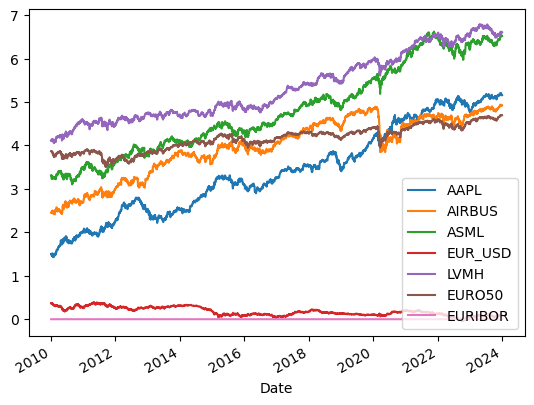

In [232]:
log_data = data
log_data[data.columns[:-1]] = np.log(data[data.columns[:-1]])

log_data.plot()

# Declaring Loss Operator

In [233]:
def loss_operator(Z, weights, Value: float = 10 ** 8):
    """
    The loss distribution is the weighted sum of negative log returns (X) multiplied by exp(Z(t) - Z(0)) where Z(x) is the log price at time x

    NOTE: For us, Z(0) = 0 as I standardised all returns at t = 0
    """
    loss = np.zeros(len(Z) - 1)
    loss_ind = Z[:-1].copy()
    T = len(Z) - 1
    t = np.arange(T)
    for Z_k, weight, name in zip(Z.values.T, weights, Z.columns):
        X_k = np.diff(Z_k)
        X_k = np.array([0] + X_k.tolist())
        X_k_shifted = X_k[1:] # from t = 2 to T
        X_k = X_k[:-1]  # from t = 1 to T - 1
        Z_k = Z_k[:-1]
        if name == 'AAPL':
            # Include EUR/USD exposure
            loss_sub = Value * weight * np.exp((Z_k - Z_k[0]) + (Z['EUR_USD'][:-1] - Z['EUR_USD'][0])) * X_k_shifted
        elif name == 'EURIBOR':
            # The time risk
            w = Value * np.exp(Z_k[0])
            loss_sub = -w * np.exp(-(T-t) * Z_k) * Z_k

            # Add credit risk
            loss_sub += Value * weight * np.exp(Z_k[0] - (T - t) * Z_k) * (T - t) * X_k
        else:
            loss_sub = Value * weight * np.exp(Z_k - Z_k[0]) * X_k_shifted
        loss += loss_sub
        loss_ind[name] = loss_sub * (1 / (weight)) if name != 'EUR_USD' else 0
    return -loss, -loss_ind

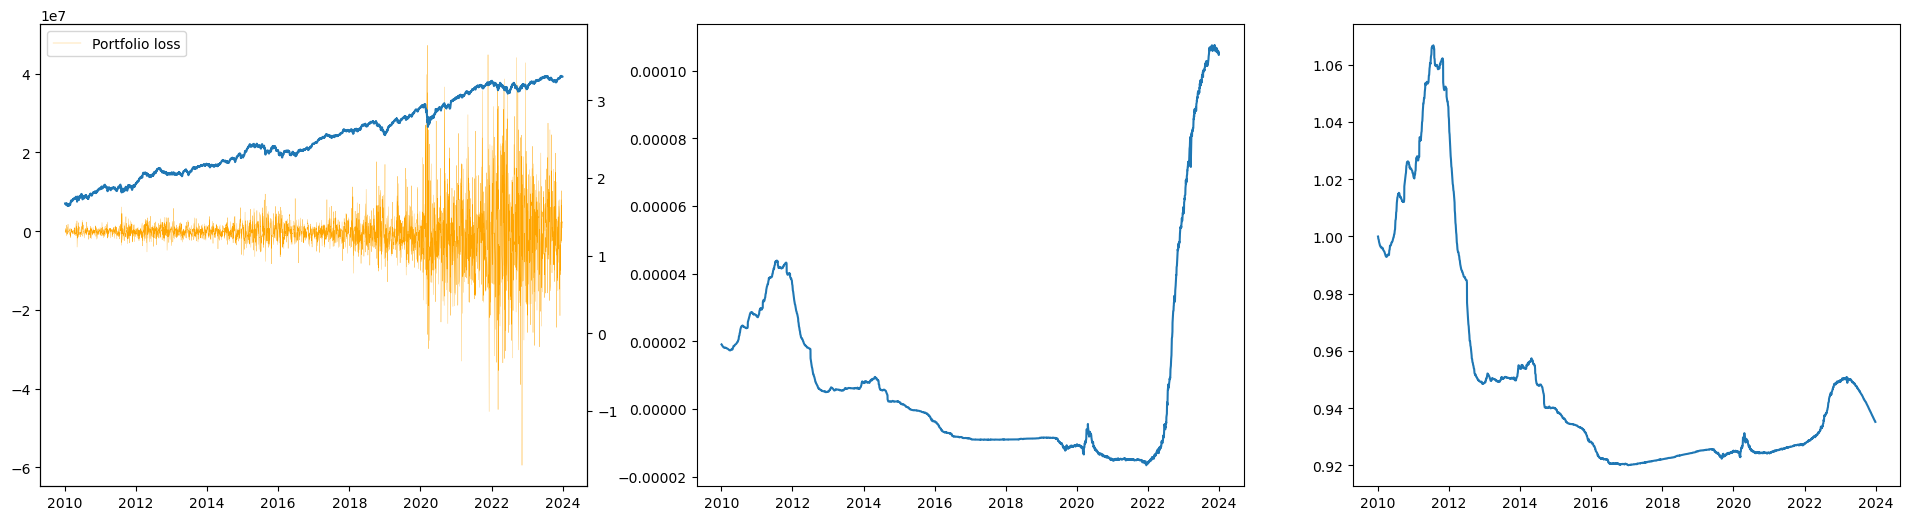

In [234]:
portfolio_loss, ind_loss = loss_operator(data, weights)
fig, axs = plt.subplots(1,3, figsize = (24, 6))
axs[0].plot(portfolio_loss, label = 'Portfolio loss', lw = 0.2, color='orange')
ax = axs[0].twinx()
PV = np.sum(weights * data, axis = 1)
ax.plot(PV)
ax.set_ylim(1.2 * max(-PV), 1.2 * max(PV))
axs[1].plot(data['EURIBOR'])
axs[2].plot(credit_val.loc[data.index])
axs[0].legend()
plt.show()

# Declaring methods to calculate VaR

### VaR CoVar

In [235]:
def Var_Cov_VaR(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    portfolio_VaR['VaR'] = pf_vol * dist(alpha, **kwargs)
    return portfolio_VaR.dropna()

def Var_Cov_ES(Vol: Any, alpha: float, dist: Callable, **kwargs) -> float:
    """
    Calculate the expected shortfall
    """
    alpha = 1 - alpha
    match dist:
        case stats.norm:
            q: float = stats.norm.isf(alpha)
            p: float = stats.norm.pdf(q)
            return Vol * p / (alpha)
        case stats.t:
            df: int | float = kwargs.get('df', 4)
            q: float = stats.t.isf(alpha, df = df)
            p: float = stats.t.pdf(q, df = df)
            return Vol * ((df + (q ** 2)) / (df - 1)) * p / (alpha)
        case _:
            raise NotImplementedError() 

In [236]:
window_size = 250 # days
VaR_HS_normal_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.norm.ppf)
VaR_HS_student4_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 4)
VaR_HS_student5_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 5)
VaR_HS_student6_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 6)

ES_HS_normal_1 = Var_Cov_ES(VaR_HS_normal_1.Vol, alpha = .95, dist = stats.norm)
ES_HS_student4_1 = Var_Cov_ES(VaR_HS_student4_1.Vol, alpha = .95, dist = stats.t, df = 4)
ES_HS_student5_1 = Var_Cov_ES(VaR_HS_student5_1.Vol, alpha = .95, dist = stats.t, df = 5)
ES_HS_student6_1 = Var_Cov_ES(VaR_HS_student6_1.Vol, alpha = .95, dist = stats.t, df = 6)

loss_df_sliced = portfolio_loss[window_size:]

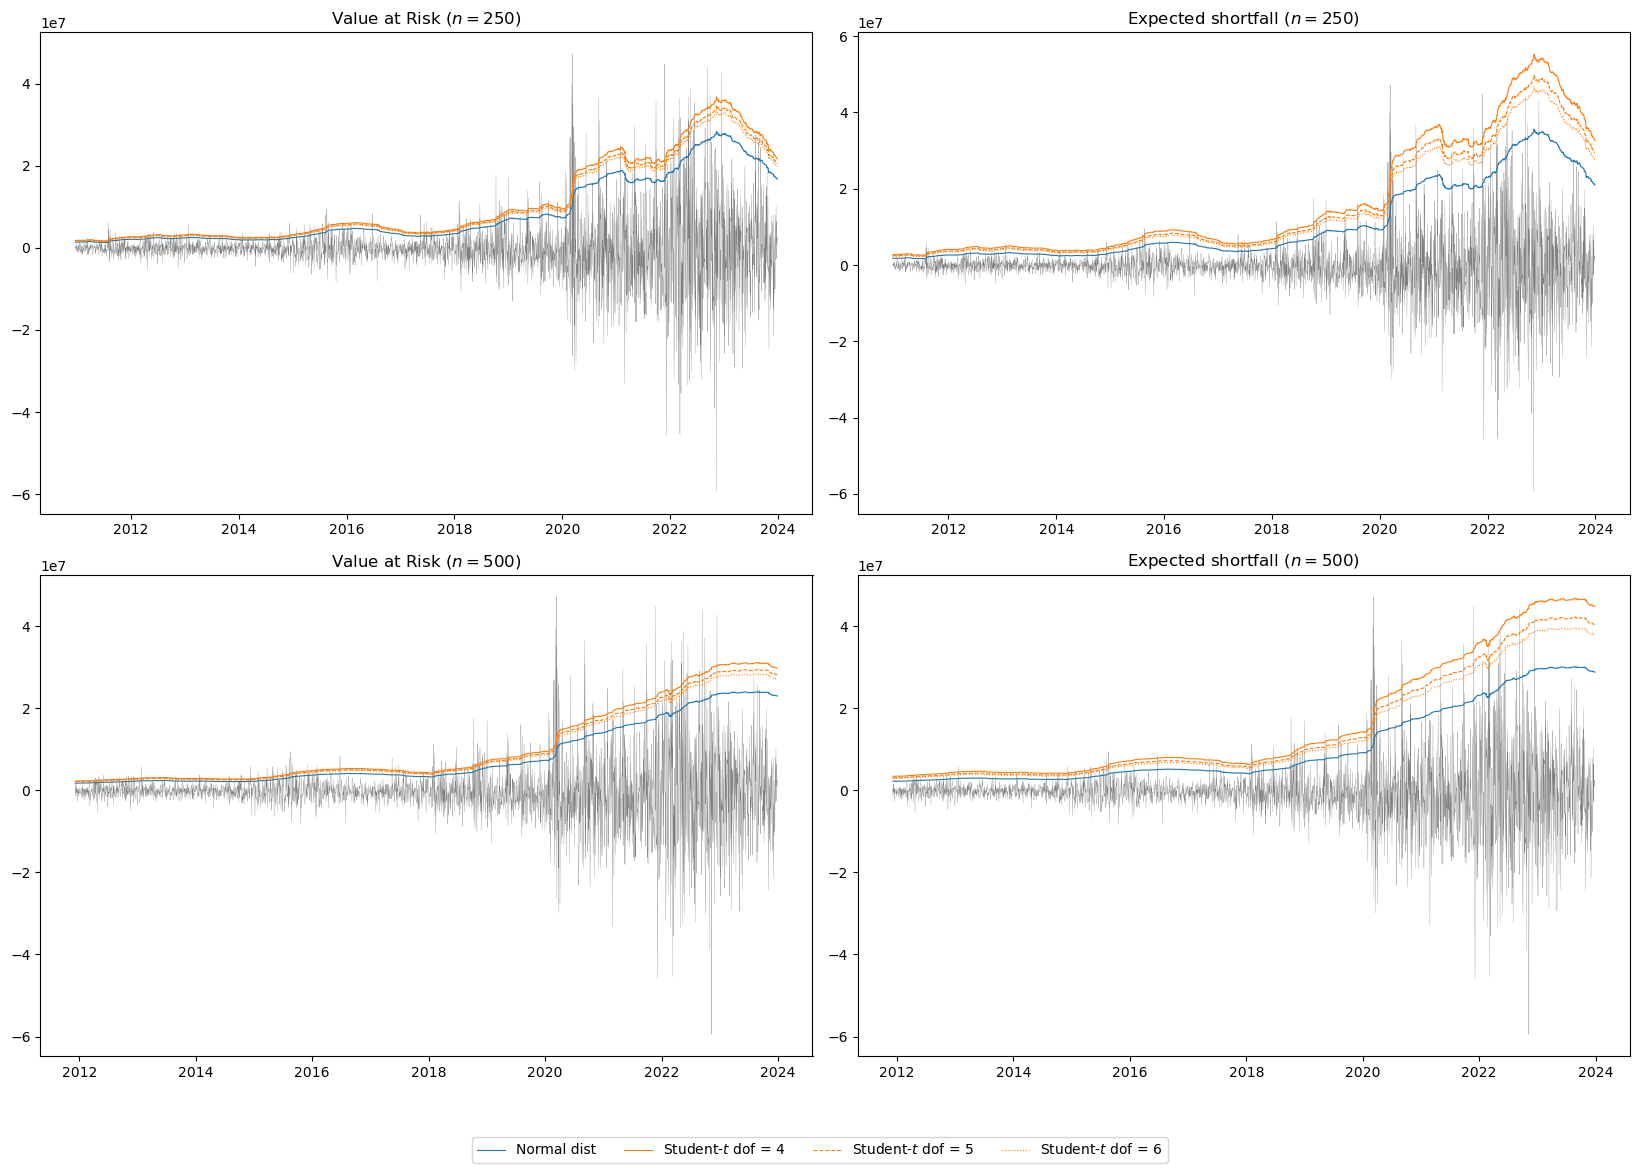

In [237]:
fig, axs = plt.subplots(2, 2, figsize = (16.5, 16.5 / 1.5)) #(8.2543, 8.2543 / 3)
axs[0,1].set_title('Expected shortfall $(n = 250)$')
axs[0,1].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[0,1].plot(ES_HS_normal_1, label = 'Normal dist', lw = .8)
axs[0,1].plot(ES_HS_student4_1, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0,1].plot(ES_HS_student5_1, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0,1].plot(ES_HS_student6_1, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0,0].set_title('Value at Risk $(n = 250)$')
axs[0,0].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[0,0].plot(VaR_HS_normal_1.VaR, label = 'Normal dist', lw = .8)
axs[0,0].plot(VaR_HS_student4_1.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0,0].plot(VaR_HS_student5_1.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0,0].plot(VaR_HS_student6_1.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)

window_size = 500 # days
VaR_HS_normal_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.norm.ppf)
VaR_HS_student4_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 4)
VaR_HS_student5_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 5)
VaR_HS_student6_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 6)

ES_HS_normal_1 = Var_Cov_ES(VaR_HS_normal_1.Vol, alpha = .95, dist = stats.norm)
ES_HS_student4_1 = Var_Cov_ES(VaR_HS_student4_1.Vol, alpha = .95, dist = stats.t, df = 4)
ES_HS_student5_1 = Var_Cov_ES(VaR_HS_student5_1.Vol, alpha = .95, dist = stats.t, df = 5)
ES_HS_student6_1 = Var_Cov_ES(VaR_HS_student6_1.Vol, alpha = .95, dist = stats.t, df = 6)

loss_df_sliced = portfolio_loss[window_size:]

axs[1,1].set_title('Expected shortfall $(n = 500)$')
axs[1,1].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[1,1].plot(ES_HS_normal_1, label = 'Normal dist', lw = .8)
axs[1,1].plot(ES_HS_student4_1, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1,1].plot(ES_HS_student5_1, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1,1].plot(ES_HS_student6_1, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[1,0].set_title('Value at Risk $(n = 500)$')
axs[1,0].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[1,0].plot(VaR_HS_normal_1.VaR, label = 'Normal dist', lw = .8)
axs[1,0].plot(VaR_HS_student4_1.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1,0].plot(VaR_HS_student5_1.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1,0].plot(VaR_HS_student6_1.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
fig.tight_layout()
plt.savefig('HS.pdf')
plt.show()

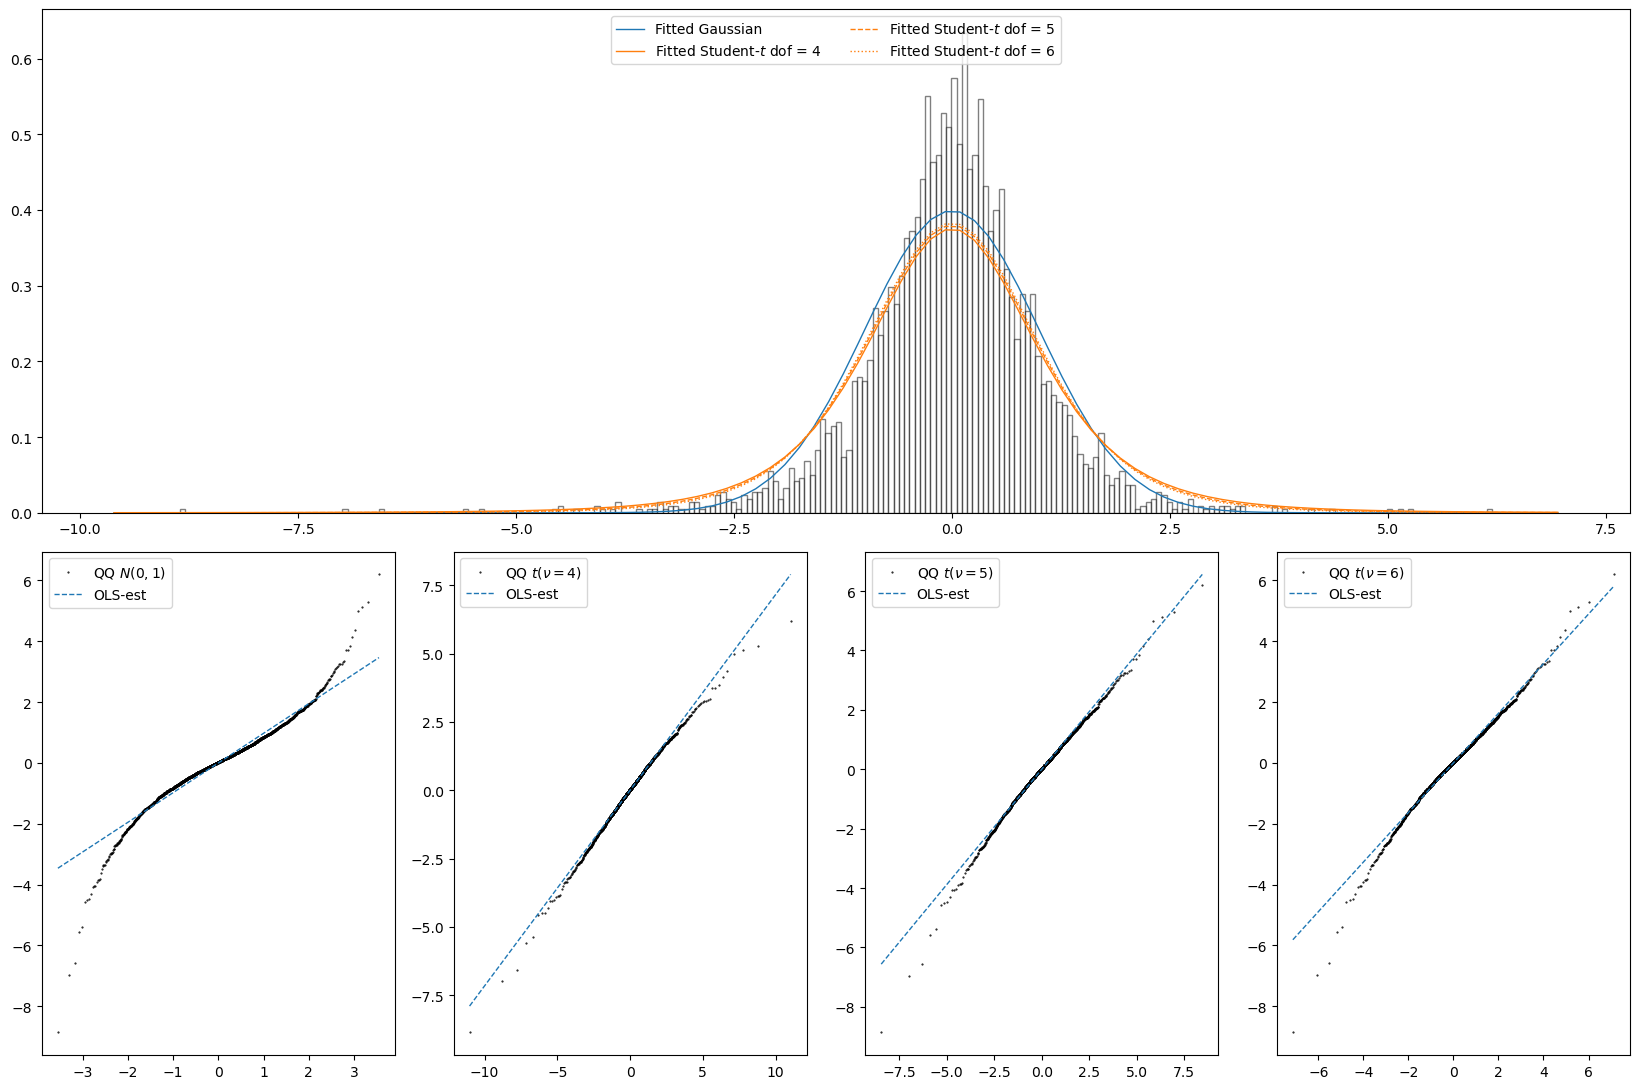

In [238]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import matplotlib as mpl

# Generate some random data
data = (log_data.diff() @ weights).dropna()
data = (data - data.mean()) / data.std()

# Create figure and subplots
# fig, axs = plt.subplots(2, 4, figsize=(12, 5))

# Plot histogram with density curve
fig = plt.figure(figsize = (16.5, 16.5 / 1.5))
gs = mpl.gridspec.GridSpec(2, 4)#, wspace=0.25, hspace=0.25) # 2x2 grid
axs = fig.add_subplot(gs[0, :]) # first row, first col
axs1 = fig.add_subplot(gs[1, 1]) # first row, second col
axs2 = fig.add_subplot(gs[1, 2])
axs3 = fig.add_subplot(gs[1, 3])
axs4 = fig.add_subplot(gs[1, 0])


axs.hist(data, bins=250, density=True, alpha=0.5, color='white', edgecolor='black')
xmin, xmax = axs.get_xlim()
x = np.linspace(xmin, xmax, 100)
pdf = stats.norm.pdf(x)
axs.plot(x, pdf, linewidth=1, ls = '-', label = 'Fitted Gaussian')
pdf = stats.t.pdf(x, loc = np.mean(data), scale = np.std(data), df = 4)
axs.plot(x, pdf, linewidth=1, ls = '-', label = 'Fitted Student-$t$ dof = 4', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs1, sparams = (4,))
axs1.get_lines()[1].set_color('C0')
axs1.get_lines()[1].set_linestyle('dashed')
axs1.get_lines()[1].set_linewidth(1)
axs1.get_lines()[0].set_marker('.')  # Set marker style to dots
axs1.get_lines()[0].set_color('black')  # Set marker color to black
axs1.get_lines()[0].set_markersize(1)  # Set marker size
# axs1.set_title('QQ Plot')

pdf = stats.t.pdf(x, df = 5)
axs.plot(x, pdf, linewidth=1, ls = 'dashed', label = 'Fitted Student-$t$ dof = 5', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs2, sparams = (5,))
axs2.get_lines()[1].set_color('C0')
axs2.get_lines()[1].set_linestyle('dashed')
axs2.get_lines()[1].set_linewidth(1)
axs2.get_lines()[0].set_marker('.')  # Set marker style to dots
axs2.get_lines()[0].set_color('black')  # Set marker color to black
axs2.get_lines()[0].set_markersize(1)  # Set marker size
# axs2.set_title('QQ Plot')

pdf = stats.t.pdf(x, df = 6)
axs.plot(x, pdf, linewidth=1, ls = 'dotted', label = 'Fitted Student-$t$ dof = 6', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs3, sparams = (6,))
axs3.get_lines()[1].set_color('C0')
axs3.get_lines()[1].set_linestyle('dashed')
axs3.get_lines()[1].set_linewidth(1)
axs3.get_lines()[0].set_marker('.')  # Set marker style to dots
axs3.get_lines()[0].set_color('black')  # Set marker color to black
axs3.get_lines()[0].set_markersize(1)  # Set marker size
# axs3.set_title('QQ Plot')

axs.legend(loc = 'upper center', ncol = 2)

# axs3.set_title('Histogram with Density')
# Plot QQ plot
stats.probplot(data, dist="norm", plot=axs4)
axs4.get_lines()[1].set_color('C0')
axs4.get_lines()[1].set_linestyle('dashed')
axs4.get_lines()[1].set_linewidth(1)
axs4.get_lines()[0].set_marker('.')  # Set marker style to dots
axs4.get_lines()[0].set_color('black')  # Set marker color to black
axs4.get_lines()[0].set_markersize(1)  # Set marker size
# axs4.set_title('QQ Plot')

axs1.set_xlabel(None)
axs2.set_xlabel(None)
axs3.set_xlabel(None)
axs4.set_xlabel(None)

axs1.set_ylabel(None)
axs2.set_ylabel(None)
axs3.set_ylabel(None)
axs4.set_ylabel(None)

axs1.set_title(None)
axs2.set_title(None)
axs3.set_title(None)
axs4.set_title(None)
# Adjust layout
# plt.tight_layout()
axs1.legend([r'QQ $t(\nu = 4)$','OLS-est'])
axs2.legend([r'QQ $t(\nu = 5)$','OLS-est'])
axs3.legend([r'QQ $t(\nu = 6)$','OLS-est'])
axs4.legend([r'QQ $N(0,1)$','OLS-est'])
# Show plot
plt.tight_layout()
plt.savefig('QQ.pdf')
plt.show()


### Other Methods

In [239]:
def volatility(omega, alpha, beta, x):
    # this function is the main volatility filter needed to obtain the results while estimating

    T =len(x)

    # Filter Volatility
    sig     = np.zeros(T)
    sig[0]  = np.var(x[:50], ddof = 0); #initialize volatility at unconditional variance

    # loop iteratively over the indices and define the volatilities in that way
    for t in range(0,T-1):
        if t % 365 == 0:
            if t != 0:
                omega = np.var(x[t - 365: t]) * (1 - alpha - beta)
        sig[t+1] = omega + alpha *  (x[t]**2) + beta * sig[t]

    return sig ** .5

def GARCH_portfolio_variance(data: pd.DataFrame, weights: np.array):
    CM: np.matrix | pd.DataFrame = data.corr().fillna(0)
    n: int = CM.shape[0]
    weights = np.array(weights)
    W = weights.reshape((n, 1)) * weights.reshape((1,len(weights)))
    CMU: np.matrix = CM * W
    
    vol_df = data * 0
    for asset in data.columns:
        x = data[asset]
        alpha, beta = .05, .93
        omega = np.var(x[:365]) * (1 - alpha - beta)
        vol_df[asset] = volatility(omega, alpha, beta, x)
      
    vol = []
    
    Sigm = vol_df.values
    for row in Sigm:
        # Variance as outer product of the weights with the covariance
        vol.append(row @ CMU @ row)
    return np.array(vol) ** .5

def GARCH_VaR(vol, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """
    return vol * dist(alpha, **kwargs)


def devol(data: pd.DataFrame, pf_loss, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    return pf_loss / portfolio_VaR.Vol

In [240]:
def Historic_Simulation(portfolio_risk: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, **kwargs) -> float:
    """
    Calculate VaR and ES using historic simulation
    """

    # Calculate the volatility
    df = pd.DataFrame([], index = portfolio_risk.index, columns = ['VaR'])
    VaR = portfolio_risk.rolling(window = window_size).quantile(alpha)
    ES  = [np.nan] * window_size
    for k in range(window_size, len(portfolio_risk)):
        _ = portfolio_risk.iloc[k - window_size: k]
        _ = _[_ >= VaR.iloc[k]]
        ES.append(np.mean(_))
        
    df['VaR'] = VaR
    df['ES'] = ES
    return df.dropna()

def filtered_HS(portfolio_risk_ind, weights, _alpha, window_size):
    Devol = pd.DataFrame([], index = portfolio_risk_ind.index)
    Vol = pd.DataFrame([], index = portfolio_risk_ind.index)
    for col in portfolio_risk_ind.columns:
        # Filter the volatility for each individual asset using the EWMA method
        x = portfolio_risk_ind[col]
        alpha = .05
        beta = 1 - alpha
        omega = 0
        vol = volatility(omega, alpha, beta, x)
        Vol[f'Vol {col}'] = vol
        Devol[f'Devol {col}'] = portfolio_risk_ind[col] / vol 
    # Calculate the portfolio volatility (not sure if correct)
    Devol = Devol.fillna(0)
    df = pd.DataFrame([], index = portfolio_risk_ind.index, columns = ['VaR'])

    # Define a rolling window VaR estimator
    ES  = [np.nan] * window_size
    VaR = [np.nan] * window_size
    for k in range(window_size, len(portfolio_risk_ind)):
        # Get the window over the devol object, and multiply with the predicted volatility
        D = Devol.iloc[k - window_size: k] * Vol.iloc[k].values

        # get the returns and calculate the VaR
        portfolio_returns = D @ weights
        VaR.append(portfolio_returns.rolling(window = window_size).quantile(_alpha).iloc[-1])
        
        _ = portfolio_returns[portfolio_returns >= VaR[k]]
        # The expected shortfall is the mean of the returns conditional on exceeding the var
        ES.append(np.mean(_))
    df['VaR'] = VaR
    df['ES'] = np.array(ES)
    return df[window_size:]#.dropna()

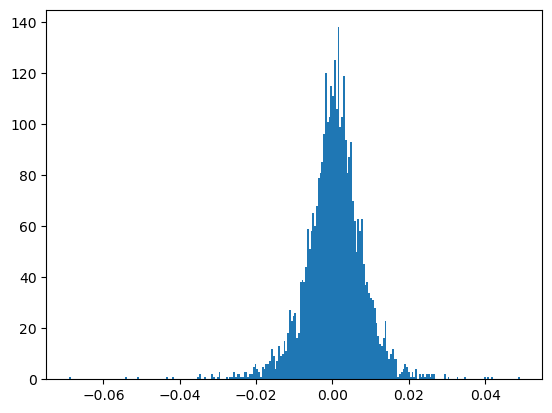

In [241]:
plt.hist(log_data.diff() @ weights, bins = 250)
plt.show()

In [242]:
VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, .95)

In [243]:
EWMA_HS = filtered_HS(ind_loss, weights, .95, window_size)
GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
VaR_GARCH = GARCH_VaR(GARCH, .95, stats.norm.ppf)
ES_GARCH = Var_Cov_ES(GARCH, .95, stats.norm)
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)

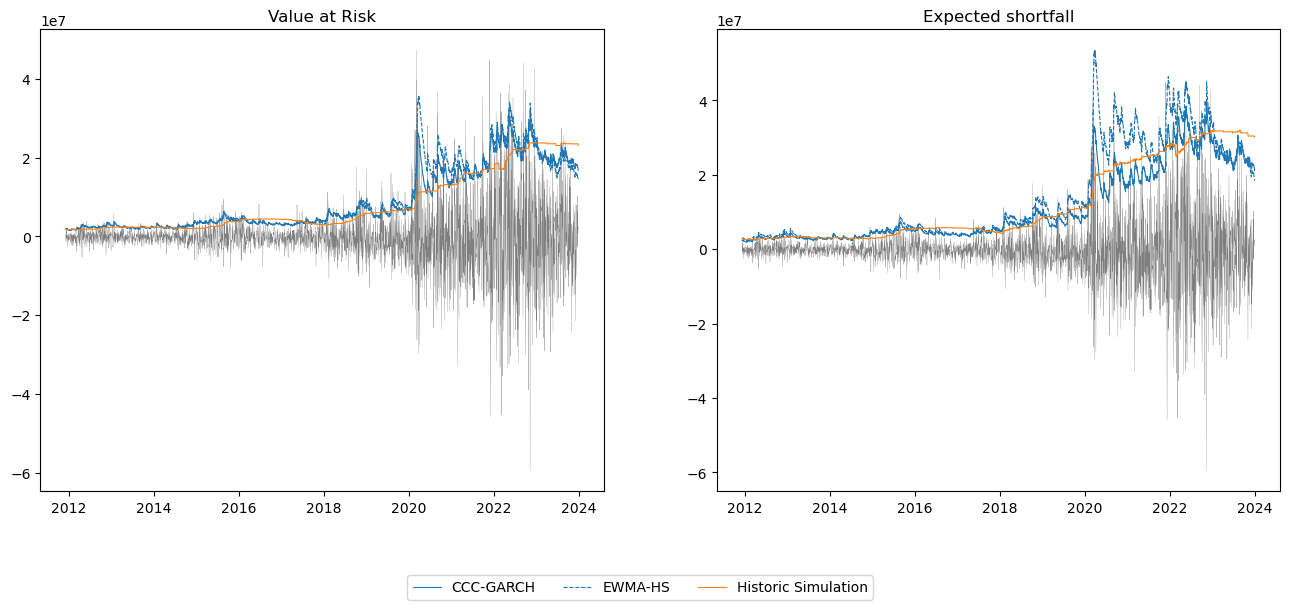

In [244]:
fig, axs = plt.subplots(1, 2, figsize = (16, 6))
# fig, axs = plt.subplots(1, 2, figsize = (8.2543, 8.2543 / 3))
axs[1].set_title('Expected shortfall')
axs[1].plot(portfolio_loss[window_size:], lw = .2, c = 'black', alpha = .5)
axs[1].plot(portfolio_loss[window_size:].index, ES_GARCH[window_size:], label = 'CCC-GARCH', lw = .8, c = 'C0')
axs[1].plot(EWMA_HS.ES, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[1].plot(VaR_ES_Historic_Simulation.ES, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0].set_title('Value at Risk')
axs[0].plot(portfolio_loss[window_size:], lw = .2, c = 'black', alpha = .5)
axs[0].plot(portfolio_loss[window_size:].index, VaR_GARCH[window_size:], label = 'CCC-GARCH', c = 'C0', lw = .8)
axs[0].plot(EWMA_HS.VaR, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[0].plot(VaR_ES_Historic_Simulation.VaR, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
plt.show()

# BackTesting

In [245]:
# Function to obtain interarrival Rates
def calculate_distances(array):
    
    # Get indices of 1s
    ones_indices = np.where(array == 1)[0]
    
    # Calculate distances between consecutive indices of 1s
    if len(ones_indices) > 1:
        distances = np.diff(ones_indices)
    else:
        distances = []  # If there's only one or no 1 at all, no distances to calculate
    
    return distances

def Backtest(VaR, ES, Loss, alpha, qqplot_arrival=False):
    """
    Perform a t-test to assess the accuracy of the Expected Shortfall (ES) estimation at the confidence level.

    Parameters:
    - VaR: Array of VaR estimates at the 97.5% confidence level.
    - ES: Array of ES estimates at the 97.5% confidence level.
    - Loss: Distribution of Observed Losses.

    """
    # Tests for VaR
    Violations_VaR = Loss > VaR
    N = len(Violations_VaR)

    if qqplot_arrival == True:
        distances = calculate_distances(Violations_VaR)
        # Checking if distances array is not empty
        if len(distances) > 0:
            # Generate a QQ-plot
            plt.figure(figsize=(12, 12))
            sm.qqplot(distances, dist=stats.expon, line="q", ax=plt.subplot(1,1,1))
            plt.title('QQ-Plot: InterArrival Distance vs. Exponential Distribution')
            plt.show()
        else:
            print("Not enough data points (1s) to generate a QQ-plot.")

    print("\nVaR Violations: ", sum(Violations_VaR))
    Z_n = (sum(Violations_VaR) - N*(1-alpha)) / np.sqrt(N*(1-alpha)*alpha) 
    critical_value = stats.norm.ppf(0.05, loc=0, scale=1)        # Using two sided test, so that both Bank and Regulators are happy
    # Check if the provided z-score is beyond the critical value for the normal distr (which approximates the Binomial well)
    if abs(Z_n) > critical_value:
        print("VaR Violations amount differs significantly from Expected\n")

    # Tests for ES
    # As an average quantity it follows normal distribution, thus we can use t test
    average_Real_ES = np.mean(Loss[Violations_VaR])     # Calculate Real World ES (the mean loss where VaR violation occured)
    average_Theoretical_ES = np.mean(ES[Violations_VaR])    # ES obtained with the Prediction Method
    print("Average ES Real and Theoretical: ", average_Real_ES, average_Theoretical_ES)

    # Calculate the two sample z-test to find if they follow different distributions
    standard_error = np.std(Loss[Violations_VaR]) / np.sqrt(np.sum(Violations_VaR))
    # Compute the z-test statistic
    Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
    ES_p = stats.norm.sf(abs(Z_Test_ES)) * 2     # Calculate the two-sided p-value from the t-test statistic
    print("ES t-Test significance of difference: ", ES_p, " | Reject if <0.05\n\n")

    return

## Obtaining Data

In [246]:
data = log_data
weights = [.2, .1, .1, .0, .1 , .1, .4]     # AAPL$, AIRBUS€, ASML€, EUR_USD, LVMH€, EURO50€, EURIBOR

start_date = '2010-01-01'
end_date = '2024-01-01'
data = data[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date))]        # Keeping only the related dates
portfolio_loss, ind_loss = loss_operator(data, weights)

In [247]:
# Obtaining Correct windows for Year Sizes

dates = data.index
indexes_year_changes = [0]
for i in range(len(dates)-1):           # Just scanning where date year index changes
    if dates[i+1].year != dates[i].year:
        indexes_year_changes.append(i+1)
indexes_year_changes.append(len(dates)-1)
print("Indexes where year changes: ", indexes_year_changes)

Indexes where year changes:  [0, 259, 517, 776, 1034, 1292, 1550, 1808, 2066, 2324, 2583, 2842, 3101, 3359, 3616]


## VaR_95

In [248]:
window_size = 258 # days
alpha = .95

### Var-CoVar


Variance Covariance Normal | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  10
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2099999.2783994293 1783970.5478554934
ES t-Test significance of difference:  0.009547513033806566  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  10
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3411992.140618728 2863215.062681877
ES t-Test significance of difference:  0.15833440575898938  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  16
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2945354.816666038 2833653.774801774
ES t-Test si

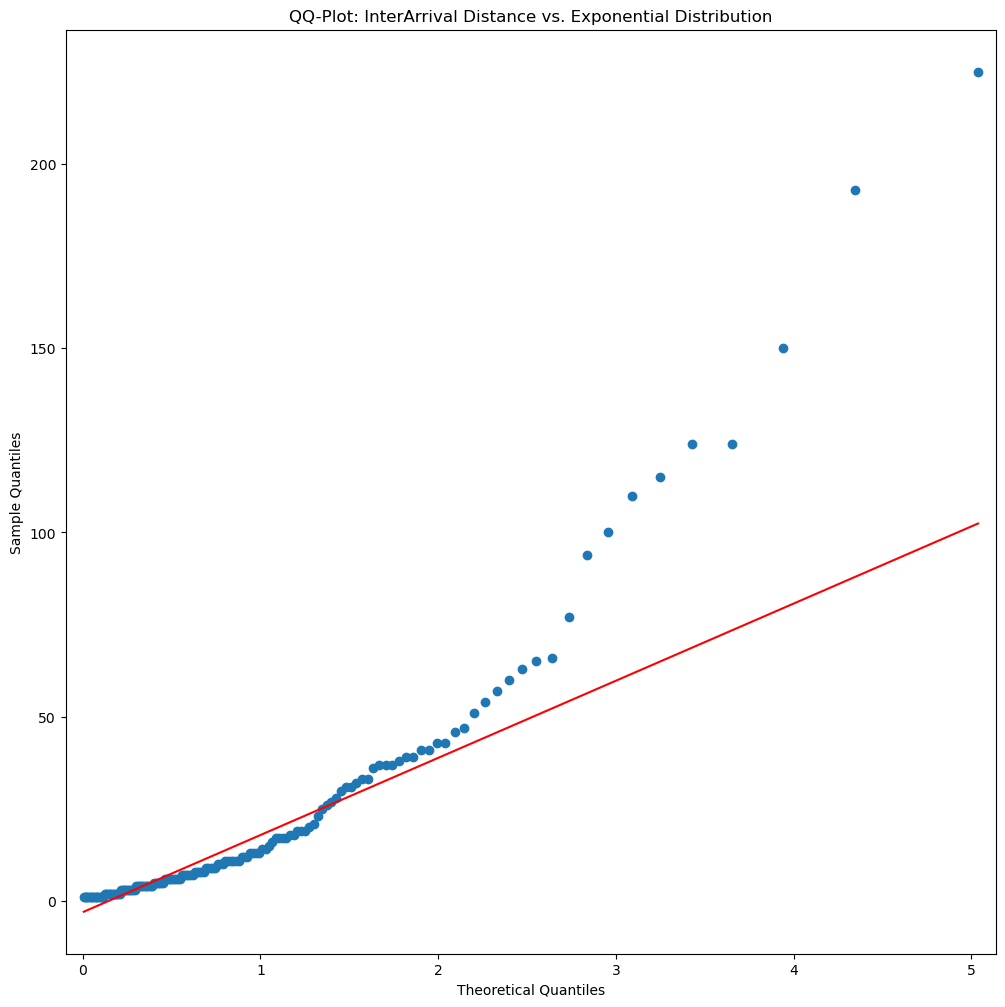


VaR Violations:  154
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  12162018.962664856 10995546.076412264
ES t-Test significance of difference:  0.2321209411265972  | Reject if <0.05




In [249]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - window_size
    end     = indexes_year_changes[i+1] - window_size
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2010+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1] - window_size
end     = indexes_year_changes[-1] - window_size
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=4


Variance Covariance t-Student_DoF=4 | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  6
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2353302.450925516 2776162.6054361886
ES t-Test significance of difference:  0.00010138635570545087  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  4397610.93854002 4620103.778807622
ES t-Test significance of difference:  0.6220871295778689  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  7
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3451674.2697611274 432634

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_30352\3221107576.py:57: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


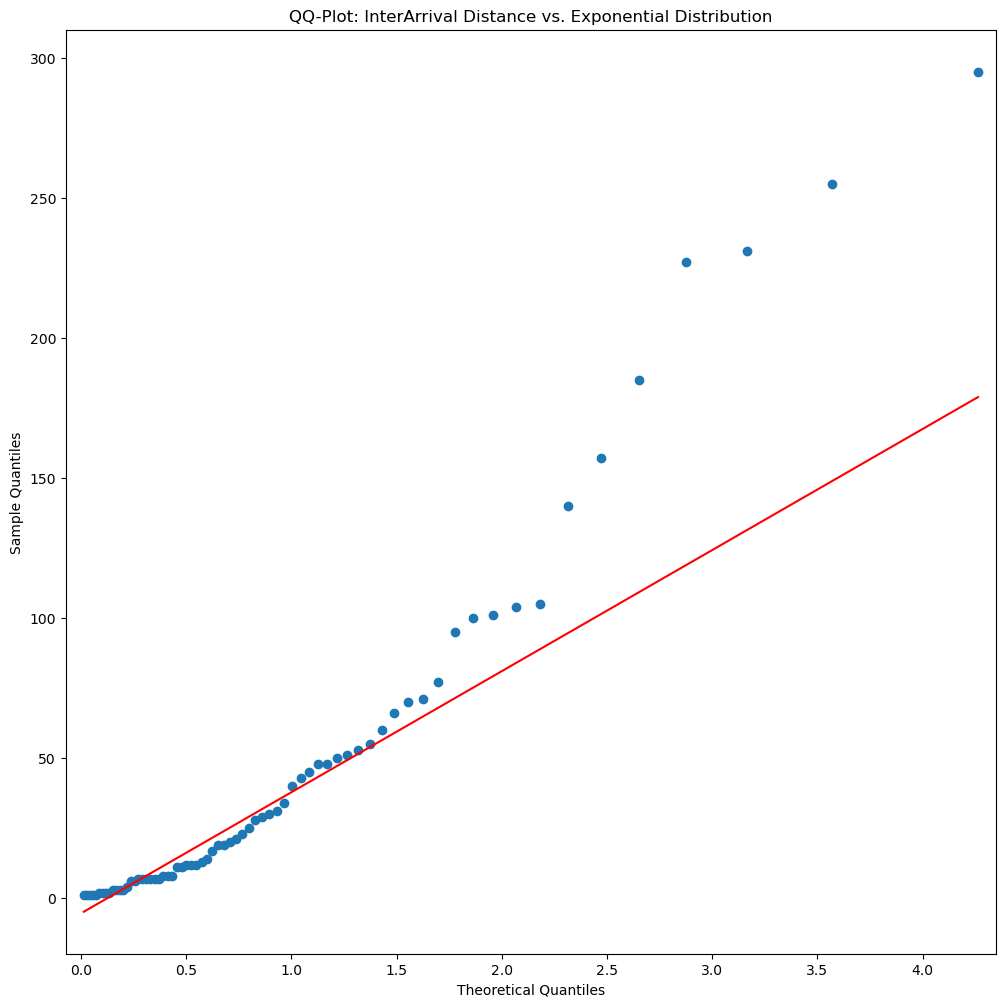


VaR Violations:  71
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  14866426.258460762 17263318.95706552
ES t-Test significance of difference:  0.1537237946320419  | Reject if <0.05




In [250]:
# For each period we find amount of VaR violations

dof = 4
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - window_size
    end     = indexes_year_changes[i+1] - window_size
    print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=' +str(2010+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1] - window_size
end     = indexes_year_changes[-1] - window_size
print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=5


Variance Covariance t-Student_DoF=5 | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  8
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2230723.165940361 2522233.6612140797
ES t-Test significance of difference:  0.00919914167566955  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  4397610.93854002 4168977.806656013
ES t-Test significance of difference:  0.6125076108420657  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  8
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3352447.275891737 3890340.03

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


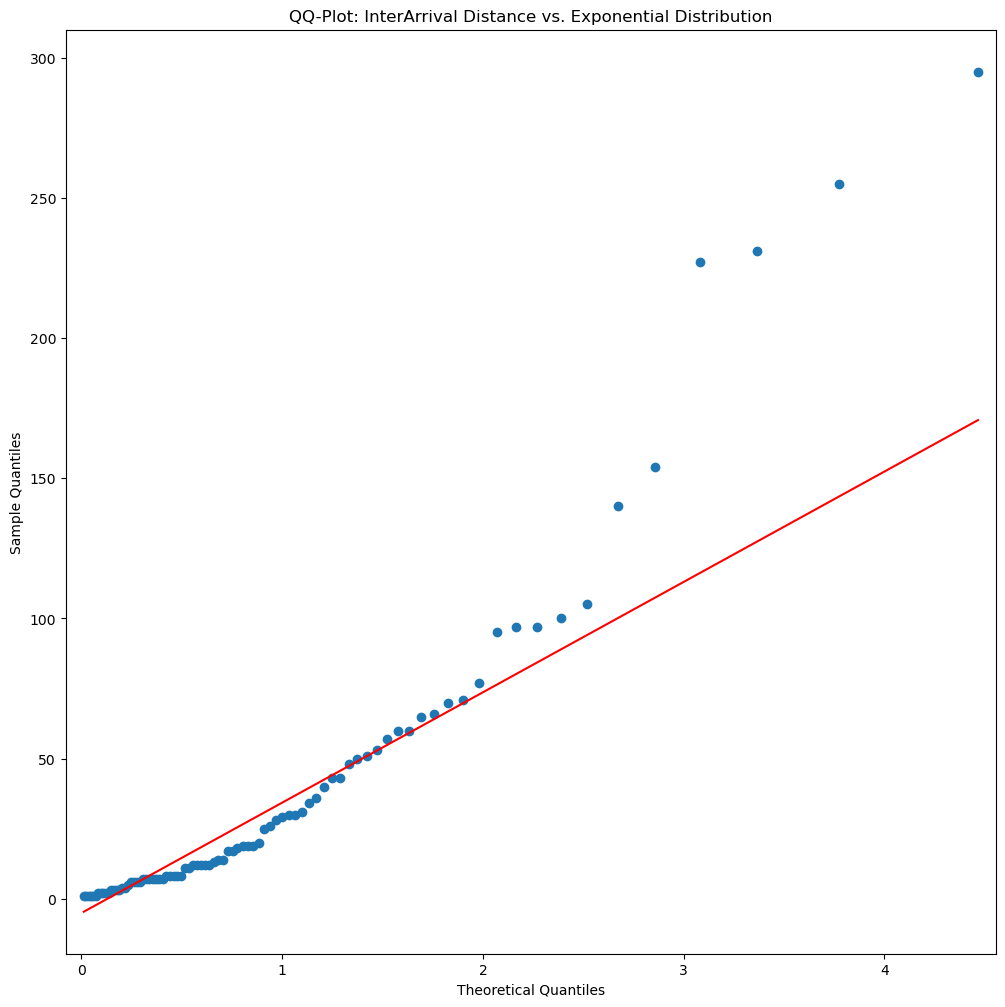


VaR Violations:  87
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  14130197.31017979 15505737.049499407
ES t-Test significance of difference:  0.3476149591966581  | Reject if <0.05




In [251]:
# For each period we find amount of VaR violations

dof = 5
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - window_size
    end     = indexes_year_changes[i+1] - window_size
    print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=' +str(2010+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1] - window_size
end     = indexes_year_changes[-1] - window_size
print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=6


Variance Covariance t-Student_DoF=6 | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  9
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2161171.6134704114 2347213.2580819926
ES t-Test significance of difference:  0.11843925294664867  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  4397610.93854002 3910209.2353808833
ES t-Test significance of difference:  0.2802515653470484  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  9
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3314350.531471423 3700488.

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


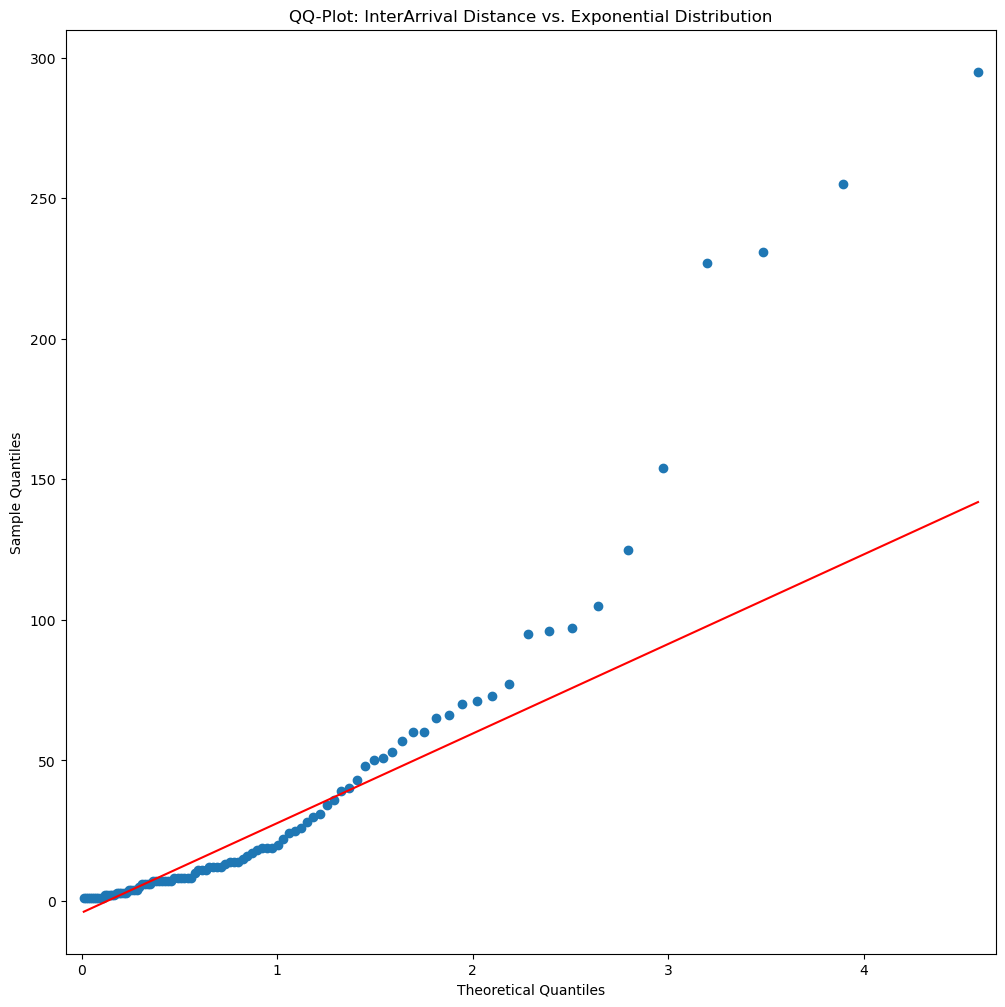


VaR Violations:  98
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  14299632.664516164 15318746.775831565
ES t-Test significance of difference:  0.45055248573989737  | Reject if <0.05




In [252]:
# For each period we find amount of VaR violations

dof = 6
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - window_size
    end     = indexes_year_changes[i+1] - window_size
    print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=' +str(2010+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1] - window_size
end     = indexes_year_changes[-1] - window_size
print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha, qqplot_arrival=True)

### Historic Simulation


Variance Covariance Normal | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  12
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  1971132.6230317366 1908674.0531970116
ES t-Test significance of difference:  0.6343522938619643  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  11
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3305664.193446796 3006333.145536488
ES t-Test significance of difference:  0.41585133503402183  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  16
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2948032.179012608 3047711.554588182
ES t-Test sign

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


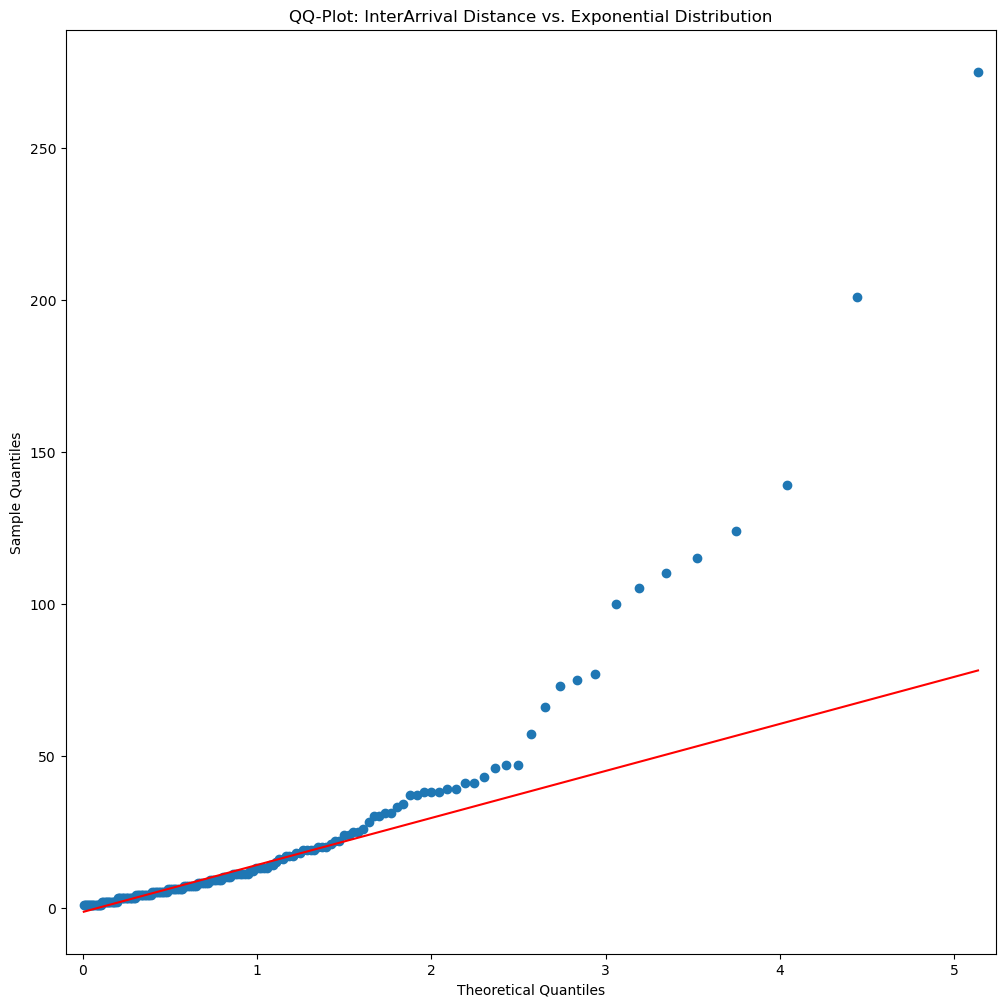


VaR Violations:  170
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  11396092.46852968 11001028.092418453
ES t-Test significance of difference:  0.6638134780669991  | Reject if <0.05




In [253]:
# For each period we find amount of VaR violations

VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, alpha)
VaR_Historic_Simulation = VaR_ES_Historic_Simulation.VaR
ES_Historic_Simulation = VaR_ES_Historic_Simulation.ES
VaR = VaR_Historic_Simulation
ES = ES_Historic_Simulation

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - window_size
    end     = indexes_year_changes[i+1] - window_size
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2010+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1] - window_size
end     = indexes_year_changes[-1] - window_size
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha, qqplot_arrival=True)

### CCC - GARCH


Variance Covariance Normal | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  8
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2138537.763886352 1895528.5254872832
ES t-Test significance of difference:  0.06538096495824443  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  12
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3175153.8410851588 2755427.543245137
ES t-Test significance of difference:  0.2431792639985716  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  15
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3003636.337669988 2894339.0903301854
ES t-Test sign

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_30352\3221107576.py:57: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


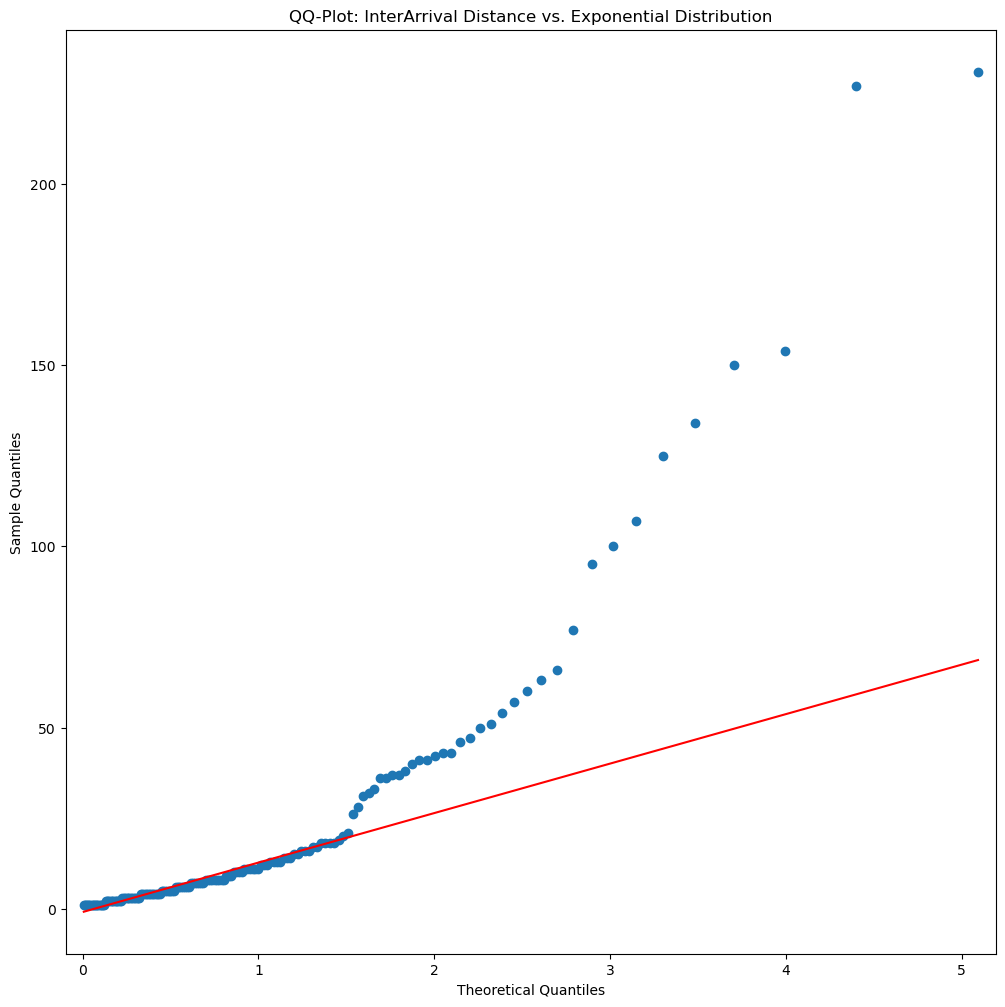


VaR Violations:  163
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  12476159.102723997 10517040.223281387
ES t-Test significance of difference:  0.03630979978324653  | Reject if <0.05




In [254]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - window_size
    end     = indexes_year_changes[i+1] - window_size
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2010+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1] - window_size
end     = indexes_year_changes[-1] - window_size
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha, qqplot_arrival=True)

### EWMA - Filtered Historical Simulation


Variance Covariance Normal | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  10
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  1999456.5663159352 1955399.060314286
ES t-Test significance of difference:  0.7498530906894418  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  12
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3175153.8410851588 3280724.8567624656
ES t-Test significance of difference:  0.7691038767760727  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  19
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2838061.44215085 2822472.574453118
ES t-Test signi

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


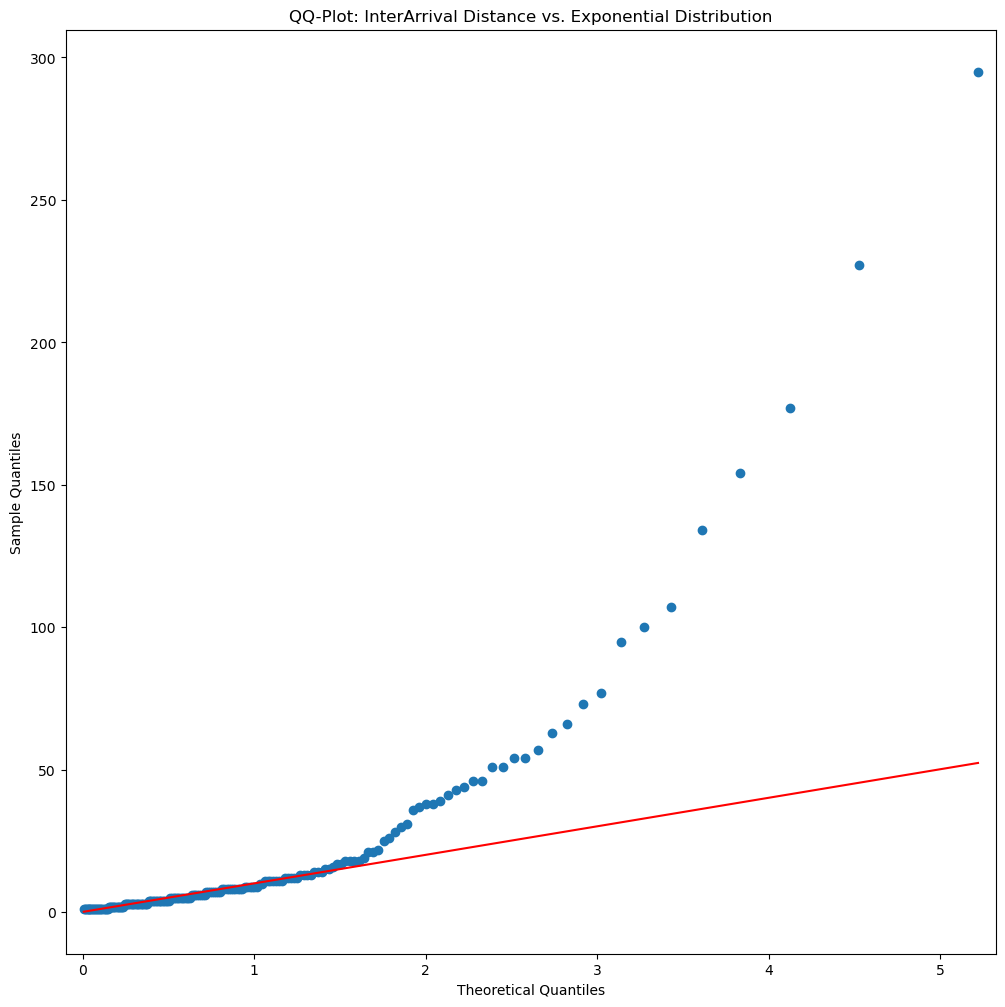


VaR Violations:  185
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  11698322.770470953 10887846.864817725
ES t-Test significance of difference:  0.34407717804141746  | Reject if <0.05




In [255]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - window_size
    end     = indexes_year_changes[i+1] - window_size
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2010+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1] - window_size
end     = indexes_year_changes[-1] - window_size
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha, qqplot_arrival=True)

## VaR_99

In [256]:
window_size = 258 # days
alpha = .99

### Var-CoVaR


Variance Covariance Normal | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  6
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2353302.450925516 2310136.5642283503
ES t-Test significance of difference:  0.6915050445350156  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  4
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  4703617.740088508 3887171.4347919505
ES t-Test significance of difference:  0.0688206067351356  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3522342.2034325995 3523894.3884117454
ES t-Test signif

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_30352\3221107576.py:57: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


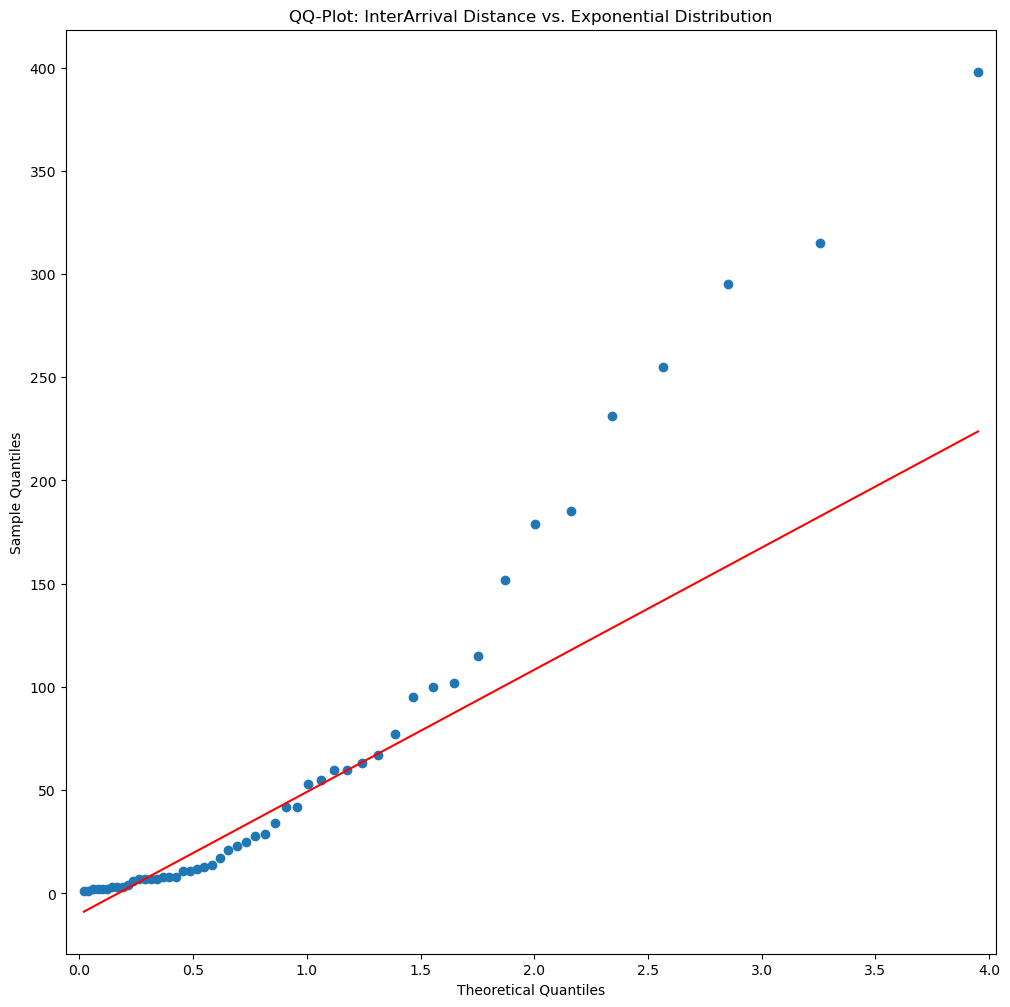


VaR Violations:  52
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  15689265.984930592 14070367.547996273
ES t-Test significance of difference:  0.4294009881245716  | Reject if <0.05




In [257]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - window_size
    end     = indexes_year_changes[i+1] - window_size
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2010+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1] - window_size
end     = indexes_year_changes[-1] - window_size
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=4


Variance Covariance t-Student_DoF=4 | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  1
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  6148516.321472948 7859877.619876948
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covar

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\PAOvi\AppData\Local\Temp\ipykernel_30352\3221107576.py:57: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


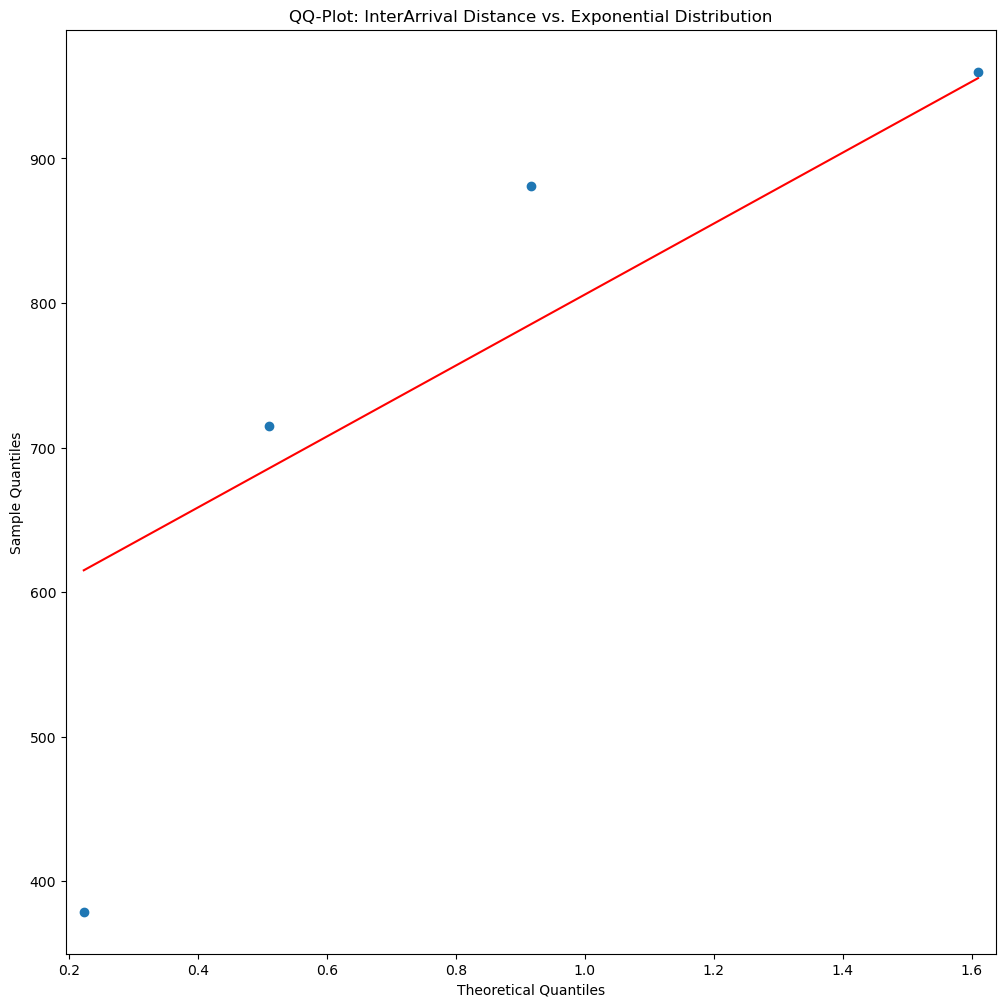


VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  22050227.065537456 27642532.738808475
ES t-Test significance of difference:  0.5062293708269077  | Reject if <0.05




In [258]:
# For each period we find amount of VaR violations

dof = 4
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - window_size
    end     = indexes_year_changes[i+1] - window_size
    print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=' +str(2010+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1] - window_size
end     = indexes_year_changes[-1] - window_size
print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=5


Variance Covariance t-Student_DoF=5 | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  1
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  6148516.321472948 6703377.749759895
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covar

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\PAOvi\AppData\Local\Temp\ipykernel_30352\3221107576.py:57: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


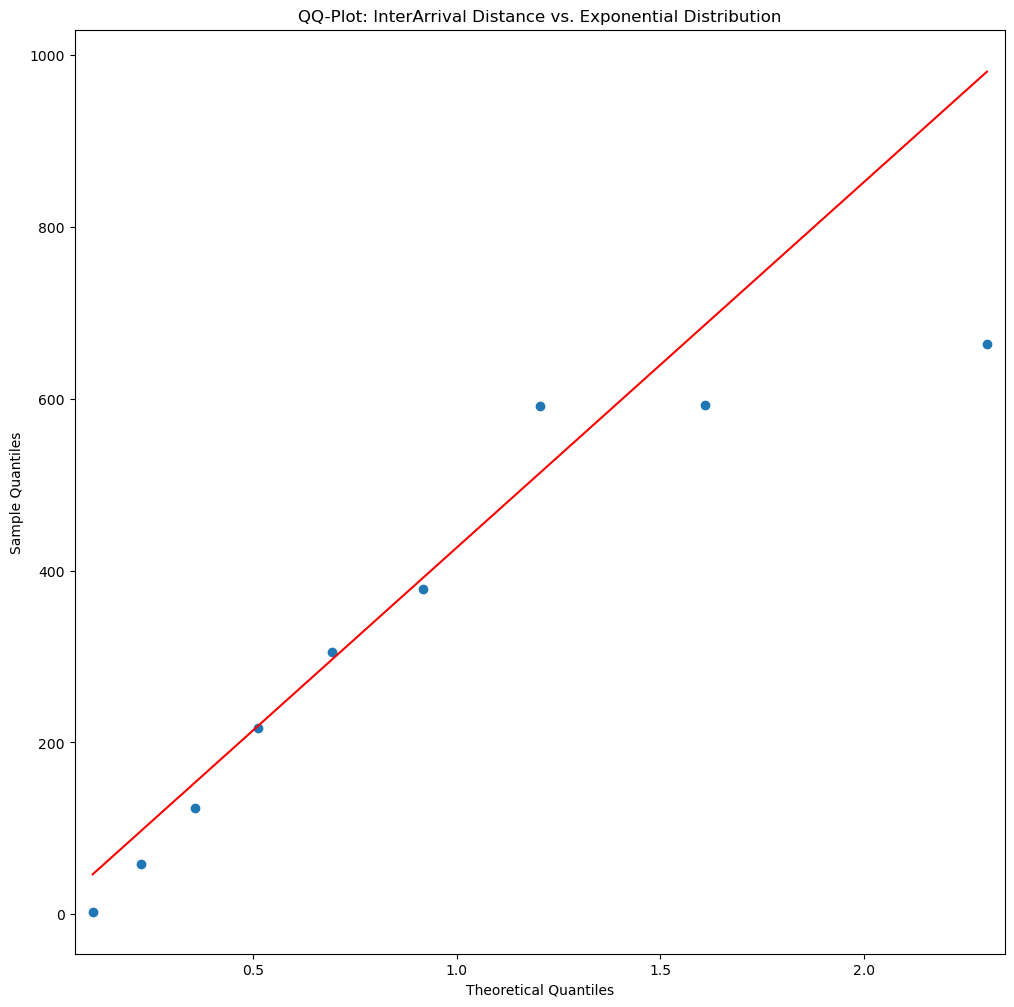


VaR Violations:  10
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  23073841.364571296 26749937.31055715
ES t-Test significance of difference:  0.4614337983935134  | Reject if <0.05




In [259]:
# For each period we find amount of VaR violations

dof = 5
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - window_size
    end     = indexes_year_changes[i+1] - window_size
    print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=' +str(2010+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1] - window_size
end     = indexes_year_changes[-1] - window_size
print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=6


Variance Covariance t-Student_DoF=6 | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  1
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2765008.00332211 3372093.2104031816
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  2
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  5316154.578512518 5892777.995988922
ES t-Test significance of difference:  0.32723193764423697  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  nan nan
ES t-Test significance of differenc

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_30352\3221107576.py:57: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


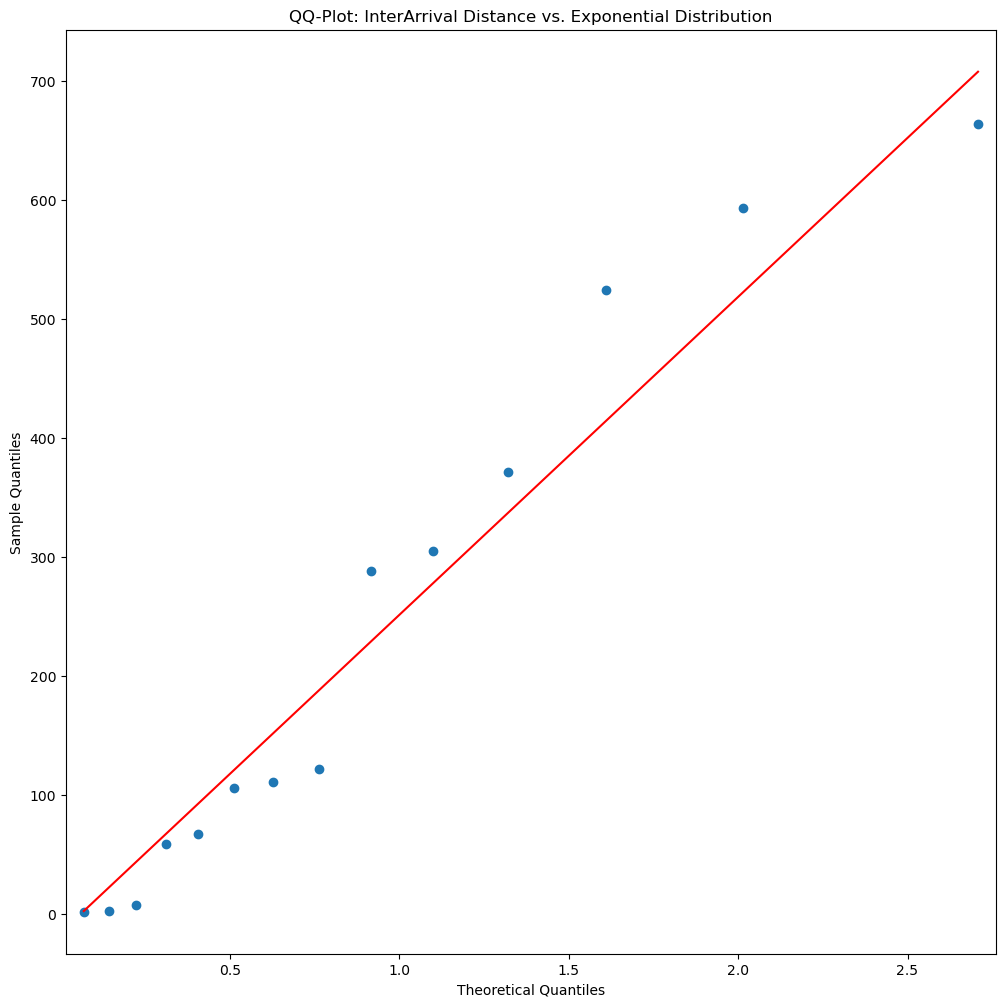


VaR Violations:  15
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  21559515.640871096 23646660.579816744
ES t-Test significance of difference:  0.6245065002017285  | Reject if <0.05




In [260]:
# For each period we find amount of VaR violations

dof = 6
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - window_size
    end     = indexes_year_changes[i+1] - window_size
    print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=' +str(2010+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1] - window_size
end     = indexes_year_changes[-1] - window_size
print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha, qqplot_arrival=True)

### Historic Simulation


Variance Covariance Normal | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  4
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2495439.0202058256 2767073.9432700146
ES t-Test significance of difference:  0.007618671546671499  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  4397610.93854002 4001470.237290164
ES t-Test significance of difference:  0.3801709342847295  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3522342.2034325995 4037556.9346869825
ES t-Test signi

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_30352\3221107576.py:57: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


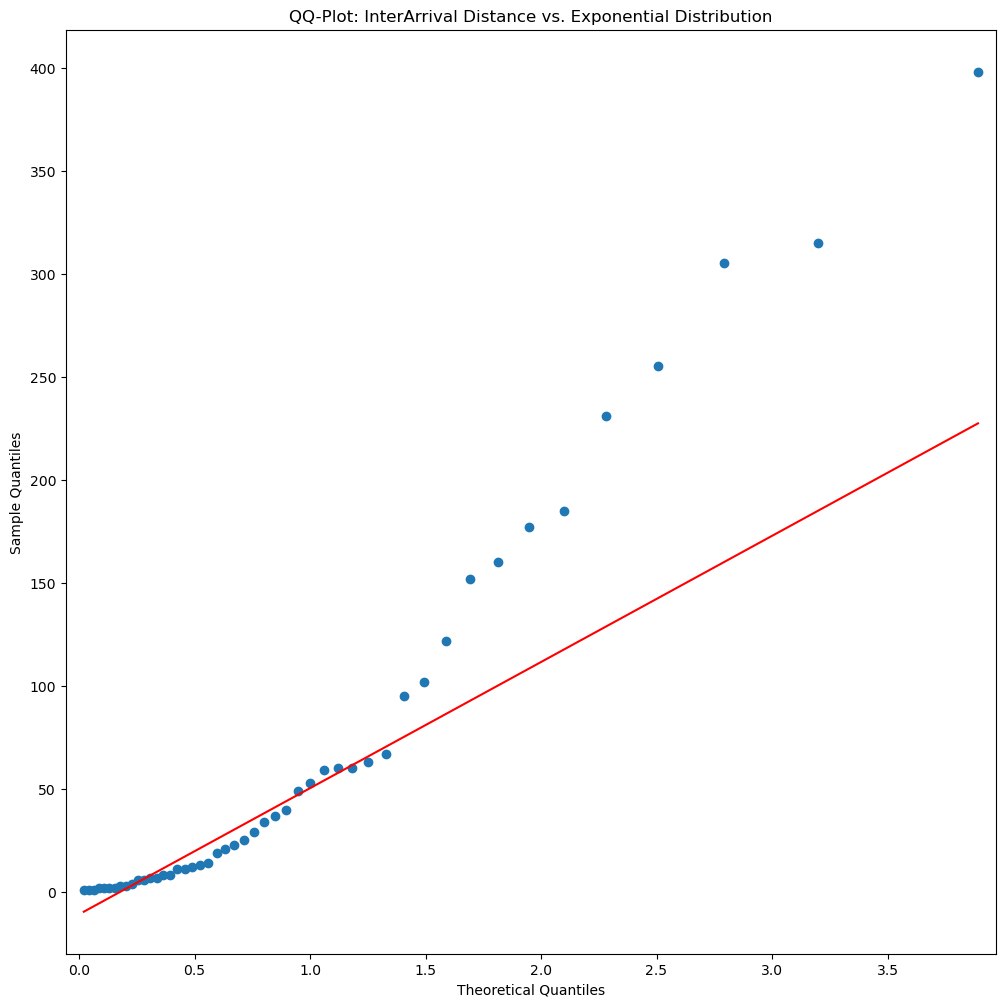


VaR Violations:  49
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  14570682.201169237 14021302.79870193
ES t-Test significance of difference:  0.7950555832292017  | Reject if <0.05




In [261]:
# For each period we find amount of VaR violations

VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, alpha)
VaR_Historic_Simulation = VaR_ES_Historic_Simulation.VaR
ES_Historic_Simulation = VaR_ES_Historic_Simulation.ES
VaR = VaR_Historic_Simulation
ES = ES_Historic_Simulation

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - window_size
    end     = indexes_year_changes[i+1] - window_size
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2010+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1] - window_size
end     = indexes_year_changes[-1] - window_size
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha, qqplot_arrival=True)

### CCC - GARCH


Variance Covariance Normal | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  4
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2450707.8710535006 2403884.3902993733
ES t-Test significance of difference:  0.7049214602210534  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  4203525.84070728 3601517.3214049214
ES t-Test significance of difference:  0.2938674369757509  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  6
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3462038.060397077 3605143.681880523
ES t-Test signific

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_30352\3221107576.py:57: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


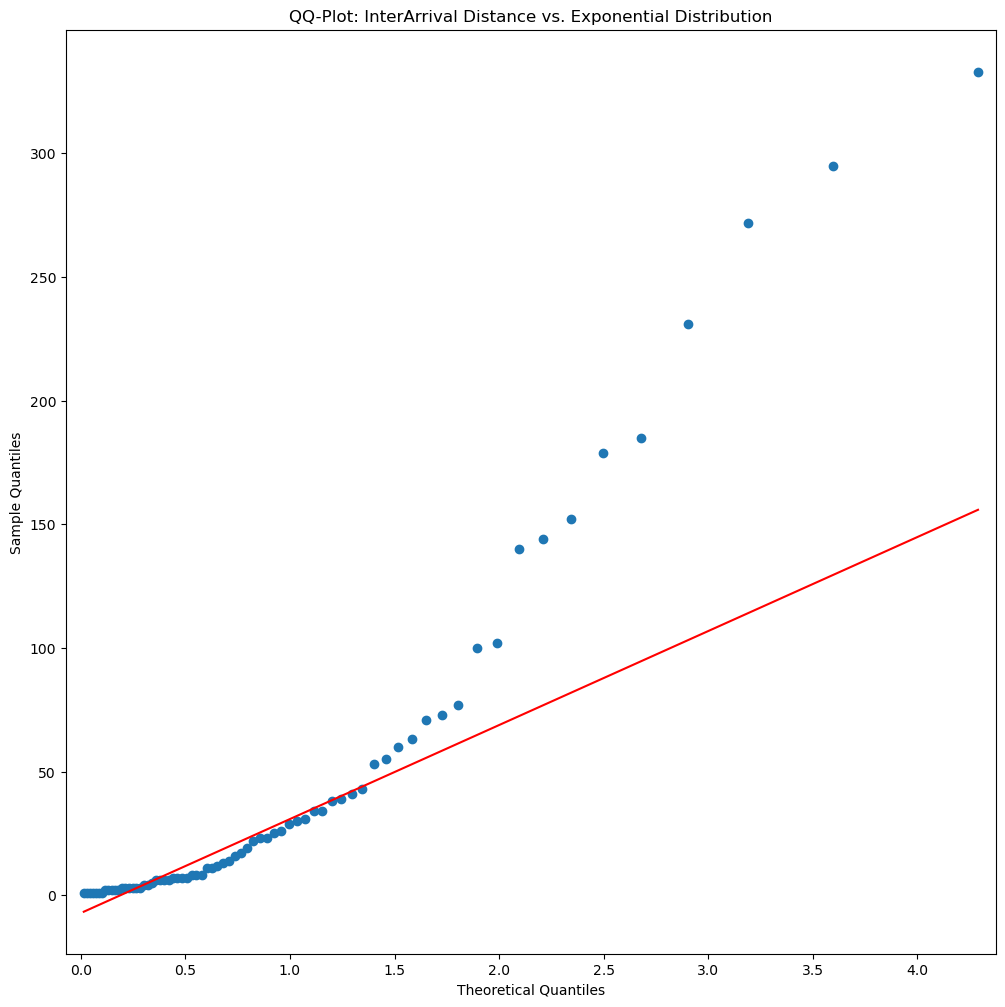


VaR Violations:  73
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  16150183.713571476 14367691.56163113
ES t-Test significance of difference:  0.28108046581604806  | Reject if <0.05




In [262]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - window_size
    end     = indexes_year_changes[i+1] - window_size
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2010+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1] - window_size
end     = indexes_year_changes[-1] - window_size
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha, qqplot_arrival=True)

### EWMA - Filtered Historical Simulation


Variance Covariance Normal | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  4
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2450707.8710535006 2496944.0801265663
ES t-Test significance of difference:  0.7084520197067841  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  4
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  4703617.740088508 5201161.644981464
ES t-Test significance of difference:  0.2674884321335249  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  6
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3462038.060397077 3589723.383534886
ES t-Test signific

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\PAOvi\AppData\Local\Temp\ipykernel_30352\3221107576.py:57: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


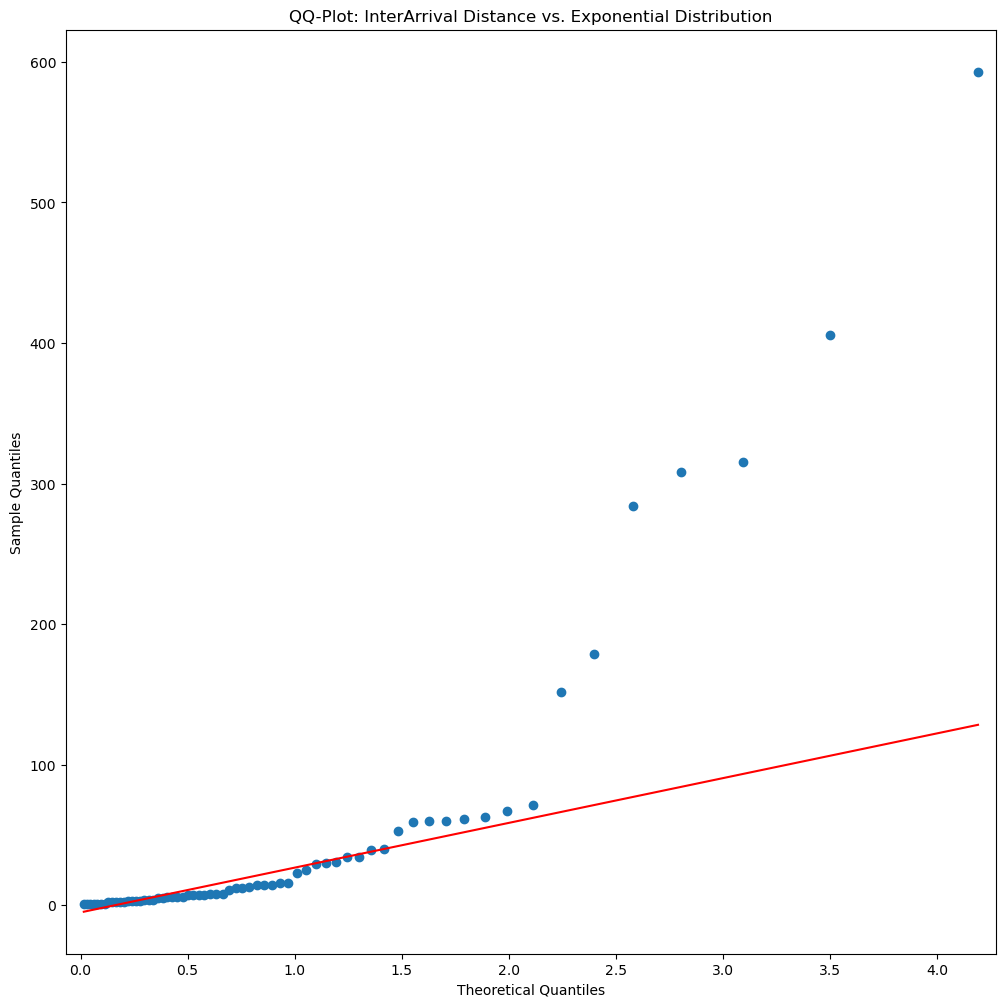


VaR Violations:  66
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  15744152.236399274 15849036.06714276
ES t-Test significance of difference:  0.9521624558550006  | Reject if <0.05




In [263]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - window_size
    end     = indexes_year_changes[i+1] - window_size
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2010+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1] - window_size
end     = indexes_year_changes[-1] - window_size
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss[start:end], alpha, qqplot_arrival=True)